# 05 — L'attention masquée : softmax causal, Q/K/V, têtes multiples

**Chapitre 2** · durée conseillée : 50 min (le cœur du chapitre) · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/chapitre_2/05_attention.ipynb)

![Parcours](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_2/figures/00_parcours.png)

Le bigramme ne voit que le caractère courant. Nous voulons que **chaque position puisse aller chercher de l'information dans les positions précédentes**, et **choisir** lesquelles sont utiles. C'est exactement ce que fait l'attention.

**Plan :**
1. Le problème : faire communiquer une position avec son passé (moyenne cumulative).
2. L'astuce matricielle et le **masque causal** (softmax masqué).
3. Un exemple **calculé à la main** des poids d'attention.
4. **Q, K, V** : rendre les poids dépendants du contenu.
5. Une tête d'attention complète, avec de vrais tenseurs.
6. **Multi-head attention**.

**Notations :** `B` batch, `T` positions, `C` canaux (caractéristiques) par position, `hs` (*head size*) = largeur d'une tête.

In [ ]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme minigpt.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/chapitre_2

In [1]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)

PyTorch 2.14.1+cu130 | périphérique : cpu


## 1. Le problème : recevoir de l'information du passé

Imaginons que chaque position `t` possède un vecteur de `C` caractéristiques, rangés dans un tenseur `x` de forme `(B, T, C)`. La manière la plus simple de « résumer le passé » de la position `t` est de **faire la moyenne** des vecteurs des positions `0, 1, …, t` :

$$\text{xbow}[b, t] = \frac{1}{t+1} \sum_{s=0}^{t} x[b, s]$$

(*bow* = *bag of words* : on mélange le passé sans tenir compte de l'ordre.)

C'est une communication très pauvre (tous les caractères passés comptent autant), mais c'est le bon point de départ. Version naïve avec deux boucles :

In [2]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t + 1]            # (t+1, C) : le passé ET la position courante
        xbow[b, t] = xprev.mean(dim=0)  # (C,)
print("x[0] =\n", x[0])
print("xbow[0] =\n", xbow[0])
print("La ligne 0 est inchangée, la ligne 1 est la moyenne des lignes 0 et 1, etc.")

x[0] =
 tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])
xbow[0] =
 tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])
La ligne 0 est inchangée, la ligne 1 est la moyenne des lignes 0 et 1, etc.


## 2. L'astuce : une moyenne pondérée est un produit matriciel

Une **matrice triangulaire inférieure** dont chaque ligne est normalisée calcule ces moyennes en un seul produit. Lisez la ligne `i` de `A` comme « **combien** la sortie `i` emprunte à chaque position `j` ».

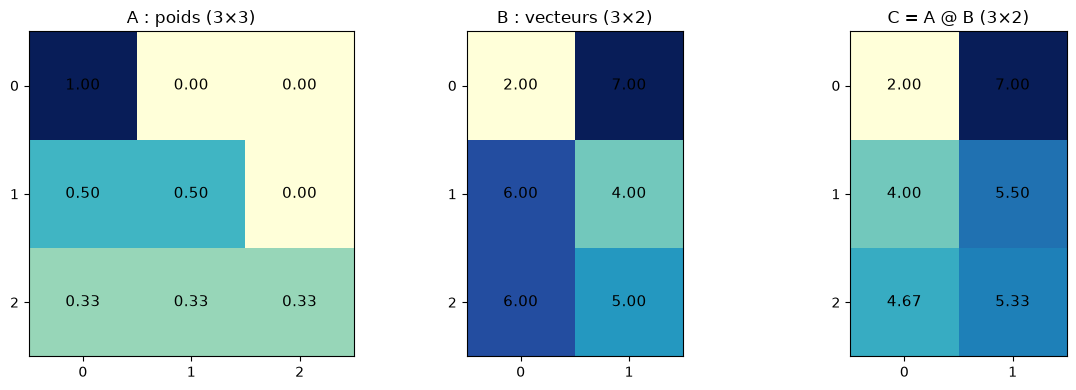

C[2,0] = 0.33×2 + 0.33×6 + 0.33×6 = 4.67


In [3]:
torch.manual_seed(42)
A = torch.tril(torch.ones(3, 3))
A = A / A.sum(1, keepdim=True)
Bm = torch.randint(0, 10, (3, 2)).float()
Cm = A @ Bm

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, M, nom in zip(axes, (A, Bm, Cm), ("A : poids (3×3)", "B : vecteurs (3×2)", "C = A @ B (3×2)")):
    ax.imshow(M, cmap="YlGnBu")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=11)
    ax.set_title(nom); ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
fig.tight_layout(); plt.show()
i, j = 2, 0
print(f"C[{i},{j}] = " + " + ".join(f"{A[i,k]:.2f}×{Bm[k,j]:.0f}" for k in range(3)) + f" = {Cm[i,j]:.2f}")

Appliqué à notre `x` : `(T, T) @ (B, T, C) → (B, T, C)`. PyTorch applique la même matrice à chaque élément du batch (*broadcasting*).

In [4]:
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x
print("boucles == produit matriciel ?", torch.allclose(xbow, xbow2, atol=1e-6))

boucles == produit matriciel ? True


### Troisième version : partir de **scores** et utiliser un **softmax masqué**

On obtient exactement la même matrice de poids ainsi :
1. partir d'une matrice de **scores** `(T, T)` (ici tous nuls) ;
2. mettre `-∞` sur les cases **interdites** (le futur, au-dessus de la diagonale) ;
3. appliquer un **softmax ligne par ligne**.

Pourquoi ce détour ? Parce que $e^{-\infty} = 0$ : les cases interdites reçoivent un poids **exactement nul**, et le softmax normalise les cases autorisées pour que **chaque ligne somme à 1**. Et surtout, dans un instant, les scores ne seront **plus nuls** : ils seront calculés à partir du contenu des tokens.

In [5]:
tril = torch.tril(torch.ones(T, T))
scores = torch.zeros((T, T))
scores = scores.masked_fill(tril == 0, float("-inf"))   # le futur est interdit
wei = F.softmax(scores, dim=-1)                         # chaque ligne : une distribution
xbow3 = wei @ x
print(wei)
print("boucles == softmax masqué ?", torch.allclose(xbow, xbow3, atol=1e-6))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])
boucles == softmax masqué ? True


### Le masque causal : apprendre sans tricher

Nous prédisons le caractère suivant. Si la position `t` pouvait lire la position `t+1`, elle lirait **la réponse** (rappel : `y[t] = x[t+1]`, notebook 03). Le modèle obtiendrait une loss parfaite à l'entraînement et serait incapable de générer.

**Règle :** la ligne `i` (position qui reçoit) peut lire la colonne `j` (position source) **seulement si `j ≤ i`**.

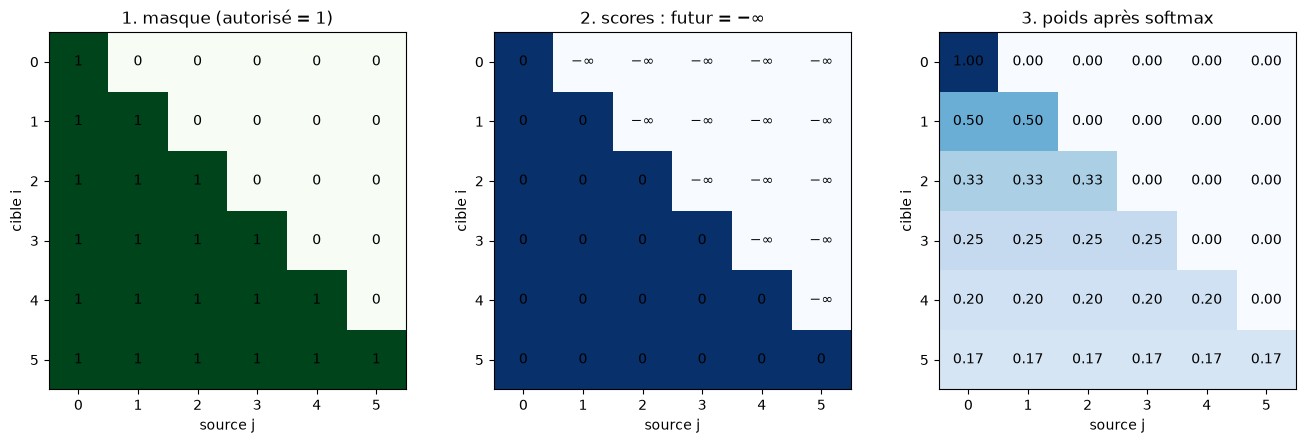

In [6]:
T_vis = 6
mask = torch.tril(torch.ones(T_vis, T_vis, dtype=torch.bool))
poids = F.softmax(torch.zeros(T_vis, T_vis).masked_fill(~mask, float("-inf")), dim=-1)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for k, (ax, nom) in enumerate(zip(axes, ["1. masque (autorisé = 1)", "2. scores : futur = −∞", "3. poids après softmax"])):
    ax.imshow(mask.float() if k < 2 else poids, cmap="Greens" if k == 0 else "Blues", vmin=0, vmax=1)
    ax.set_title(nom); ax.set_xlabel("source j"); ax.set_ylabel("cible i")
    for i in range(T_vis):
        for j in range(T_vis):
            txt = ("1" if mask[i, j] else "0") if k == 0 else (("0" if mask[i, j] else "−∞") if k == 1 else f"{poids[i, j]:.2f}")
            ax.text(j, i, txt, ha="center", va="center", fontsize=10)
fig.tight_layout(); plt.show()

**Question :** la position 3 peut-elle lire la position 2 ? La position 4 ? *(Oui ; non.)*

---
## 3. Exemple calculé à la main : des scores aux poids

Prenons le mot **`chat`** (4 positions) et supposons qu'on nous donne les **scores** suivants (nous verrons au §4 d'où ils viennent). Le score `S[i, j]` dit « à quel point la position `i` s'intéresse à la position `j` ».

| | `c` (j=0) | `h` (j=1) | `a` (j=2) | `t` (j=3) |
|---|---|---|---|---|
| **`c`** (i=0) | 1 | 3 | 0 | 2 |
| **`h`** (i=1) | 2 | 0 | 1 | 1 |
| **`a`** (i=2) | 1 | 3 | 1 | 0 |
| **`t`** (i=3) | 0 | 2 | 2 | 1 |

**Étape 1 — masquer.** Tout ce qui est au-dessus de la diagonale devient `−∞` (le `3` de la ligne `c` disparaît : `c` ne peut pas voir `h`).

**Étape 2 — softmax, ligne par ligne.** Pour la ligne `a` (i = 2), seules les colonnes 0, 1, 2 sont autorisées :

$$
w_{2,j} = \frac{e^{S_{2,j}}}{e^{1} + e^{3} + e^{1}} \quad\Rightarrow\quad
w_{2,\cdot} = \left[\frac{2{,}72}{25{,}52},\ \frac{20{,}09}{25{,}52},\ \frac{2{,}72}{25{,}52},\ 0\right] = [0{,}11;\ 0{,}79;\ 0{,}11;\ 0]
$$

La position `a` va chercher **79 %** de son information chez `h`.

**Étape 3 — mélanger les valeurs.** Chaque position transmet un vecteur `v_j`. La sortie de la position 2 est la moyenne pondérée :
$\text{out}_2 = 0{,}11\, v_0 + 0{,}79\, v_1 + 0{,}11\, v_2 + 0 \cdot v_3$.

Vérifions avec PyTorch :

In [7]:
mot = list("chat")
S = torch.tensor([[1., 3., 0., 2.],
                  [2., 0., 1., 1.],
                  [1., 3., 1., 0.],
                  [0., 2., 2., 1.]])
masque = torch.tril(torch.ones(4, 4))
S_masque = S.masked_fill(masque == 0, float("-inf"))
W = F.softmax(S_masque, dim=-1)

print("Scores masqués :\n", S_masque)
print("\nPoids (chaque ligne somme à 1) :")
for i, c in enumerate(mot):
    print(f"  {c} : " + "  ".join(f"{w:.2f}" for w in W[i].tolist()), f"  (somme = {W[i].sum():.0f})")

valeurs = torch.tensor([[1., 0.],    # v_c
                        [0., 1.],    # v_h
                        [1., 1.],    # v_a
                        [5., 5.]])   # v_t : ne doit JAMAIS atteindre c, h, a
out = W @ valeurs
print("\nSorties (poids @ valeurs) :")
for i, c in enumerate(mot):
    print(f"  out_{c} = {out[i].tolist()}")
print("\nLa grosse valeur de 't' (5, 5) n'apparaît que dans out_t : le futur ne fuit pas.")

Scores masqués :
 tensor([[1., -inf, -inf, -inf],
        [2., 0., -inf, -inf],
        [1., 3., 1., -inf],
        [0., 2., 2., 1.]])

Poids (chaque ligne somme à 1) :
  c : 1.00  0.00  0.00  0.00   (somme = 1)
  h : 0.88  0.12  0.00  0.00   (somme = 1)
  a : 0.11  0.79  0.11  0.00   (somme = 1)
  t : 0.05  0.40  0.40  0.15   (somme = 1)

Sorties (poids @ valeurs) :
  out_c = [1.0, 0.0]
  out_h = [0.8807970285415649, 0.11920291185379028]
  out_a = [0.21301394701004028, 0.8934929370880127]
  out_t = [1.1883647441864014, 1.5337865352630615]

La grosse valeur de 't' (5, 5) n'apparaît que dans out_t : le futur ne fuit pas.


**Point clé :** un score de `3` contre `1` donne déjà un poids de 0,79 contre 0,11. L'exponentielle du softmax **amplifie les écarts** : quelques unités de score suffisent pour que l'attention se concentre sur une position.

---
## 4. Q, K, V : des poids qui dépendent du contenu

Jusqu'ici, les scores étaient **donnés**. Dans l'attention, chaque position les **calcule** à partir de son propre vecteur `x_t`, grâce à trois projections linéaires **apprises** :

| Vecteur | Calcul | Rôle | Analogie (bibliothèque) |
|---|---|---|---|
| **Query** `q_t` | `x_t @ Wq` | ce que la position **cherche** | la question que je pose au bibliothécaire |
| **Key** `k_t` | `x_t @ Wk` | ce que la position **annonce contenir** | l'étiquette sur le dos d'un livre |
| **Value** `v_t` | `x_t @ Wv` | ce que la position **transmet** si on la choisit | le contenu du livre |

Le score entre la position `i` et la position `j` est le **produit scalaire** de la question de `i` avec l'étiquette de `j` :

$$S_{ij} = \frac{q_i \cdot k_j}{\sqrt{hs}}$$

Grand produit scalaire = la clé de `j` « répond » à la question de `i` = gros poids après softmax. Puis on récupère les **valeurs** pondérées. En matrices, pour toutes les positions à la fois :

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\text{masque}\!\left(\frac{Q K^\top}{\sqrt{hs}}\right)\right) V$$

![Une tête d'attention](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_2/figures/05_tete_attention.png)

**Pourquoi séparer K et V ?** Ce qui permet de **trouver** une information (la clé) n'est pas forcément l'information qu'on veut **récupérer** (la valeur). Par exemple, une voyelle peut chercher « la consonne juste avant moi » (clé = position) mais vouloir récupérer « quelle consonne c'est » (valeur = identité).

### Construire une tête « regarde le caractère précédent » à la main

Pour se convaincre que Q/K peuvent exprimer une règle utile, fabriquons des poids **à la main** (un réseau entraîné peut en apprendre de semblables) :
- chaque position `t` a pour vecteur `x_t` un one-hot de sa **position** ;
- `Wk = Id` : la clé de `t` est « je suis à la position `t` » ;
- `Wq` décale d'un cran : la query de `t` est « je cherche la position `t − 1` ».

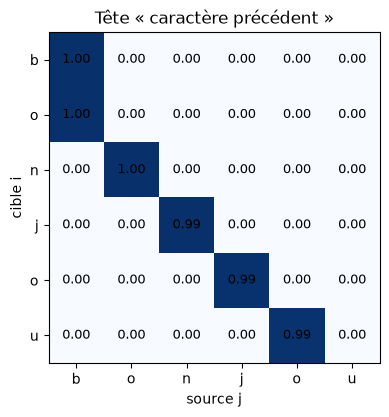

Chaque position (sauf la première) met ~99 % de son attention sur la position précédente.
Avec V = identité du caractère, la sortie de 'n' contiendrait 'o' : la tête a COPIÉ le contexte.


In [8]:
T4 = 6
x_pos = torch.eye(T4)                          # x_t = one-hot de la position t
Wk = torch.eye(T4)                             # clé  : « je suis la position t »
Wq = 6 * torch.diag(torch.ones(T4 - 1), -1)    # query : « je cherche t-1 » (le 6 rend le choix net)
q, k = x_pos @ Wq, x_pos @ Wk
S = (q @ k.T).masked_fill(torch.tril(torch.ones(T4, T4)) == 0, float("-inf"))
W = F.softmax(S, dim=-1)

lettres = list("bonjour"[:T4])
fig, ax = plt.subplots(figsize=(5, 4.3))
ax.imshow(W, cmap="Blues", vmin=0, vmax=1)
for i in range(T4):
    for j in range(T4):
        ax.text(j, i, f"{W[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(T4), lettres); ax.set_yticks(range(T4), lettres)
ax.set_xlabel("source j"); ax.set_ylabel("cible i"); ax.set_title("Tête « caractère précédent »")
plt.show()
print("Chaque position (sauf la première) met ~99 % de son attention sur la position précédente.")
print("Avec V = identité du caractère, la sortie de 'n' contiendrait 'o' : la tête a COPIÉ le contexte.")

Avec une telle tête, la position `n` de `bonjour` reçoit l'information « le caractère d'avant était `o` » : c'est déjà plus qu'un bigramme. Un vrai modèle **apprend** ses `Wq`, `Wk`, `Wv` par descente de gradient, et peut découvrir des règles bien plus subtiles dont nous même ne connaissons pas la signification.

---
## 5. Une tête d'attention avec de vrais tenseurs

Passons à des projections `nn.Linear` aléatoires sur un petit batch : `B = 2`, `T = 4`, `C = 6`, `hs = 3`.

- `nn.Linear(C, hs, bias=False)` transforme **chaque position séparément** : `(B, T, C) → (B, T, hs)`. Elle ne fait **pas** communiquer les positions.
- La communication a lieu dans `q @ k.transpose(-2, -1)` : chaque query est comparée à chaque clé **du même exemple**.

x       : (2, 4, 6)
q       : (2, 4, 3)
k       : (2, 4, 3)
v       : (2, 4, 3)
scores  : (2, 4, 4)
weights : (2, 4, 4)
out     : (2, 4, 3)


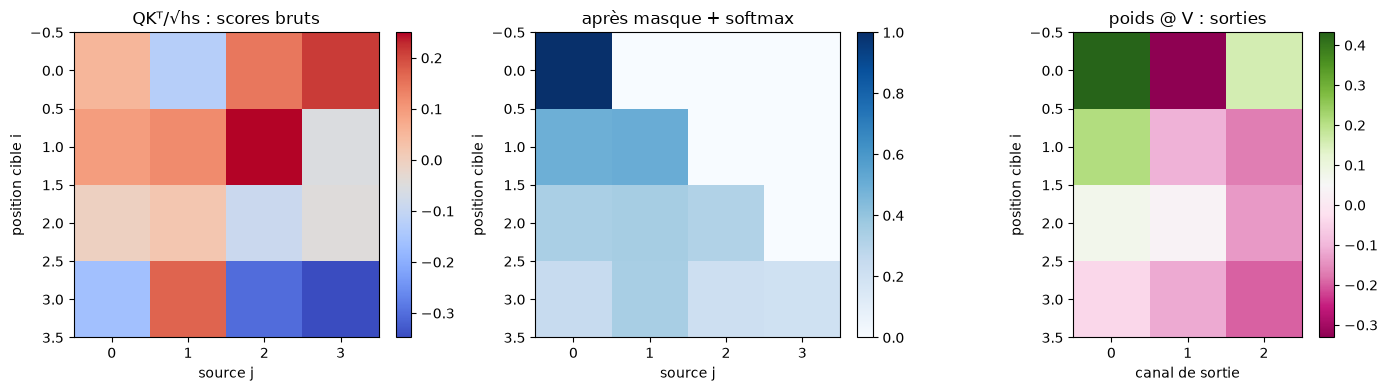

In [9]:
torch.manual_seed(2026)
B, T, C, hs = 2, 4, 6, 3
x_att = torch.randn(B, T, C)
query = nn.Linear(C, hs, bias=False)
key = nn.Linear(C, hs, bias=False)
value = nn.Linear(C, hs, bias=False)

q, k, v = query(x_att), key(x_att), value(x_att)             # (B, T, hs) chacun
scores = q @ k.transpose(-2, -1) / math.sqrt(hs)             # (B, T, T)
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
weights = F.softmax(scores.masked_fill(~causal, float("-inf")), dim=-1)  # (B, T, T)
out = weights @ v                                            # (B, T, hs)

for nom, t in [("x", x_att), ("q", q), ("k", k), ("v", v), ("scores", scores), ("weights", weights), ("out", out)]:
    print(f"{nom:8s}: {tuple(t.shape)}")
assert torch.allclose(weights.sum(-1), torch.ones(B, T))
assert (weights[:, ~causal] == 0).all()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, M, titre, cmap in [(axes[0], scores[0], "QKᵀ/√hs : scores bruts", "coolwarm"),
                           (axes[1], weights[0], "après masque + softmax", "Blues"),
                           (axes[2], out[0], "poids @ V : sorties", "PiYG")]:
    im = ax.imshow(M.detach(), cmap=cmap); ax.set_title(titre); plt.colorbar(im, ax=ax, fraction=.046)
axes[0].set_xlabel("source j"); axes[1].set_xlabel("source j"); axes[2].set_xlabel("canal de sortie")
for ax in axes: ax.set_ylabel("position cible i")
plt.tight_layout(); plt.show()

### Pourquoi transposer K ?

Pour un exemple du batch, `Q` et `K` sont de forme `(T, hs)`. On veut comparer **chaque ligne de Q à chaque ligne de K** : il faut `(T, hs) @ (hs, T) = (T, T)`. La case `(i, j)` est le produit scalaire $q_i \cdot k_j$. `transpose(-2, -1)` échange les deux dernières dimensions et laisse la dimension batch tranquille.

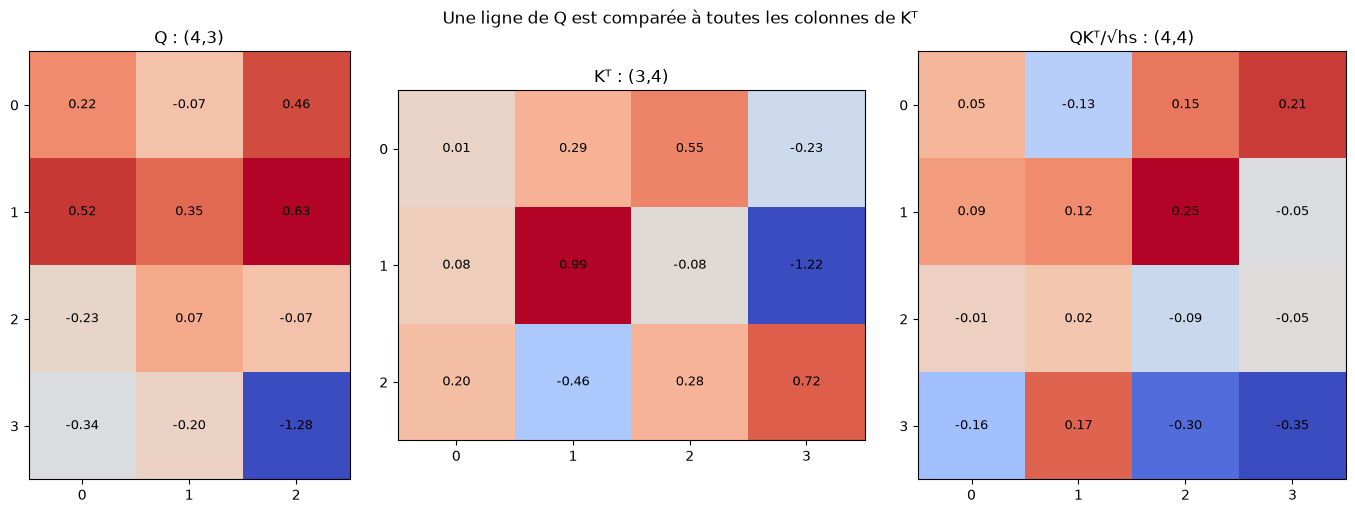

score(2,1) = (q_2 · k_1) / √3 = 0.0190 = 0.0190


In [10]:
q0, k0 = q[0].detach(), k[0].detach()
qk0 = q0 @ k0.T / math.sqrt(hs)
fig, axes = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 4, 4]})
for ax, M, titre in [(axes[0], q0, f"Q : ({T},{hs})"), (axes[1], k0.T, f"Kᵀ : ({hs},{T})"), (axes[2], qk0, f"QKᵀ/√hs : ({T},{T})")]:
    ax.imshow(M, cmap="coolwarm")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(titre); ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
fig.suptitle("Une ligne de Q est comparée à toutes les colonnes de Kᵀ"); fig.tight_layout(); plt.show()
i, j = 2, 1
print(f"score({i},{j}) = (q_{i} · k_{j}) / √{hs} = {(q0[i] @ k0[j]).item() / math.sqrt(hs):.4f} = {qk0[i, j]:.4f}")

### Pourquoi `poids @ V` redonne un vecteur par position ?

Une ligne des poids contient `T` coefficients ; elle sert à faire la somme pondérée des `T` vecteurs de `V` (chacun de taille `hs`). On obtient **un** vecteur de taille `hs` par position : `(T, T) @ (T, hs) → (T, hs)`. Les poids portent sur les **positions**, les valeurs portent sur les **caractéristiques**.

In [11]:
A0, V0, Y0 = weights[0].detach(), v[0].detach(), out[0].detach()
position, canal = 2, 0
termes = " + ".join(f"{A0[position, j]:.2f}×{V0[j, canal]:.2f}" for j in range(T))
print(f"out[{position},{canal}] = {termes} = {Y0[position, canal]:.4f}")
print("Le poids de la position future 3 est nul : elle n'apporte rien.")

out[2,0] = 0.34×0.43 + 0.35×-0.01 + 0.31×-0.23 + 0.00×-0.47 = 0.0715
Le poids de la position future 3 est nul : elle n'apporte rien.


### Pourquoi diviser par $\sqrt{hs}$ ?

Si `q` et `k` ont des composantes de variance 1, leur produit scalaire (somme de `hs` termes) a une variance d'environ `hs`. Avec de grands scores, le softmax devient **presque un argmax** : toute l'attention va sur une seule position, et les gradients des autres positions deviennent quasi nuls. Diviser par $\sqrt{hs}$ ramène la variance des scores à ~1 (Vaswani et al., 2017, §3.2.1).

> La variance mesure à quel point des valeurs s’écartent de leur moyenne. Plus elle est grande, plus les valeurs sont dispersées.

variance de q·k          : 18.44   (≈ hs = 16)
variance de q·k / √hs    : 1.15   (≈ 1)


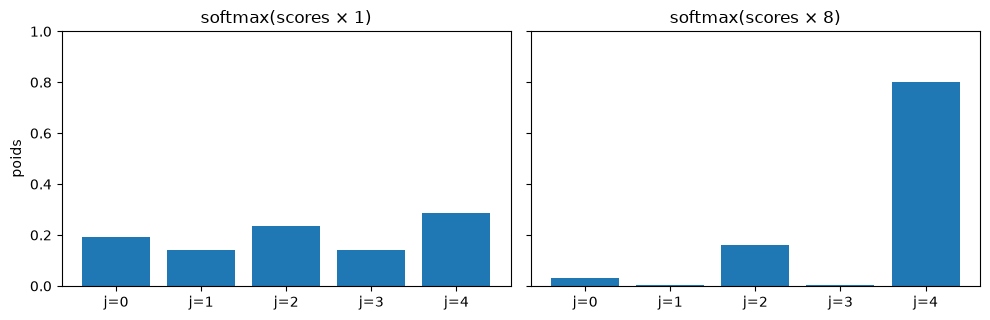

In [ ]:
torch.manual_seed(1337)
hs_test = 16
k_ = torch.randn(4, 8, hs_test); q_ = torch.randn(4, 8, hs_test)
print(f"variance de q·k          : {(q_ @ k_.transpose(-2, -1)).var():.2f}   (≈ hs = {hs_test})")
print(f"variance de q·k / √hs    : {(q_ @ k_.transpose(-2, -1) * hs_test**-0.5).var():.2f}   (≈ 1)")

exemple = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, echelle in zip(axes, [1, 8]):
    p = torch.softmax(exemple * echelle, dim=-1)
    ax.bar(range(5), p); ax.set_ylim(0, 1); ax.set_title(f"softmax(scores × {echelle})")
    ax.set_xticks(range(5), [f"j={j}" for j in range(5)])
axes[0].set_ylabel("poids"); fig.tight_layout(); plt.show()

### La classe `Head`

Tout ce que nous venons de faire, rangé dans un `nn.Module` (c'est le code de `minigpt.py`) :
- `register_buffer("tril", ...)` : le masque est sauvegardé avec le modèle et suit `.to(device)`, mais **n'est pas un paramètre** ;
- `self.tril[:T, :T]` : on peut appeler la tête sur une séquence **plus courte** que `block_size` (utile pendant la génération) ;
- le `dropout` sur les poids sera expliqué au notebook 06.

In [13]:
class Head(nn.Module):
    """Une tête d'auto-attention causale."""

    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)    # « ce que je contiens »
        self.query = nn.Linear(n_embd, head_size, bias=False)  # « ce que je cherche »
        self.value = nn.Linear(n_embd, head_size, bias=False)  # « ce que je transmets »
        # Le masque n'est PAS un paramètre : register_buffer le range avec le modèle
        # (et le déplace sur le GPU avec lui) sans que l'optimiseur y touche.
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                          # (B, T, hs)
        q = self.query(x)                                        # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5      # (B, T, T) scores
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))  # interdire le futur
        wei = F.softmax(wei, dim=-1)                             # chaque ligne somme à 1
        wei = self.dropout(wei)
        v = self.value(x)                                        # (B, T, hs)
        return wei @ v                                           # (B, T, hs)


torch.manual_seed(0)
tete = Head(n_embd=32, head_size=8, block_size=16, dropout=0.0)
x = torch.randn(1, 10, 32)
y1 = tete(x)

# Test de causalité : modifier la position 7 ne doit changer AUCUNE sortie avant 7
x2 = x.clone(); x2[0, 7] = torch.randn(32)
y2 = tete(x2)
diff = (y1 - y2).abs().amax(dim=-1)[0]
print("changement de la sortie, position par position :", [f"{d:.2f}" for d in diff.tolist()])
assert diff[:7].max() == 0, "le futur a fui !"
print("Positions 0 à 6 inchangées : la tête est causale.")

changement de la sortie, position par position : ['0.00', '0.00', '0.00', '0.00', '0.00', '0.00', '0.00', '0.22', '0.19', '0.17']
Positions 0 à 6 inchangées : la tête est causale.


---
## 6. Multi-head attention : plusieurs questions en parallèle

Une tête ne calcule **qu'une** distribution de poids par position : elle ne peut poser qu'**une question** à la fois (« où est la voyelle précédente ? »). Mais pour prédire le caractère suivant, plusieurs informations sont utiles en même temps : le caractère précédent, le début du mot, le dernier espace, le nom du personnage qui parle…

**Solution :** faire tourner `h` têtes **en parallèle**, chacune avec ses propres `Wq`, `Wk`, `Wv`, puis **concaténer** leurs sorties sur l'axe des canaux.

![Multi-head attention](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_2/figures/05_multi_tetes.png)

- Avec `C = 64` et `h = 4`, chaque tête a `hs = 64 / 4 = 16` canaux ; la concaténation redonne `4 × 16 = 64` canaux.
- La **projection** finale `proj` (Linear `C → C`) mélange ce que les têtes ont trouvé et prépare l'addition résiduelle (notebook 07).
- On concatène sur `dim=-1` (les canaux) : les `T` positions ne sont **jamais** concaténées entre elles.
- Coût : `h` têtes de taille `C/h` coûtent autant qu'**une** tête de taille `C`. On gagne en diversité sans payer plus.

In [14]:
class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, concaténées puis reprojetées sur n_embd canaux."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.heads = nn.ModuleList(
            [Head(n_embd, head_size, block_size, dropout) for _ in range(n_head)]
        )
        self.proj = nn.Linear(n_head * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)    # (B, T, n_head*hs)
        return self.dropout(self.proj(out))                     # (B, T, n_embd)


torch.manual_seed(0)
mha = MultiHeadAttention(n_embd=64, n_head=4, block_size=32, dropout=0.0)
x = torch.randn(2, 10, 64)
print("entrée :", tuple(x.shape))
for i, h in enumerate(mha.heads):
    print(f"  tête {i} -> {tuple(h(x).shape)}")
print("concaténation ->", tuple(torch.cat([h(x) for h in mha.heads], dim=-1).shape))
print("sortie ->", tuple(mha(x).shape))
print("paramètres :", minigpt.compter_parametres(mha),
      "= 4 têtes × 3 × (64×16) + proj (64×64 + 64)")

entrée : (2, 10, 64)
  tête 0 -> (2, 10, 16)
  tête 1 -> (2, 10, 16)
  tête 2 -> (2, 10, 16)
  tête 3 -> (2, 10, 16)
concaténation -> (2, 10, 64)
sortie -> (2, 10, 64)
paramètres : 16448 = 4 têtes × 3 × (64×16) + proj (64×64 + 64)


Au notebook 09, nous afficherons les **poids d'attention d'un modèle entraîné** : on verra que les têtes se spécialisent.

---
## 7. Ce qu'il faut garder en tête (notes du grand maitre Karpathy)

- **L'attention est un mécanisme de communication.** Les positions sont des nœuds d'un graphe orienté ; chaque nœud agrège les informations des nœuds qui pointent vers lui, avec des poids qui dépendent des données.
- **L'attention n'a aucune notion d'espace ou d'ordre.** Elle agit sur un *ensemble* de vecteurs. C'est pourquoi il faudra **ajouter une information de position** aux embeddings (notebook 08).
- **Les exemples du batch ne communiquent jamais** : les calculs sont faits indépendamment pour chaque `b`.
- **Encodeur vs décodeur :** supprimer la ligne `masked_fill` donne une attention d'**encodeur** (tout le monde voit tout le monde). Nous la gardons : nous sommes un **décodeur**.
- **Self- vs cross-attention :** ici Q, K, V viennent du **même** `x` (*self*). Dans la cross-attention (notebook 04), Q vient du décodeur et K, V d'un encodeur.

## À retenir

- Les poids d'attention forment une matrice `(T, T)` par exemple et par tête ; chaque ligne est une distribution (softmax).
- **Masque causal :** score `−∞` sur le futur avant le softmax ⇒ poids exactement 0 ⇒ aucune fuite de la réponse.
- $\text{softmax}(\text{masque}(QK^\top/\sqrt{hs}))\,V$ : Q·K décident **où regarder**, V décide **quoi récupérer**.
- `Wq`, `Wk`, `Wv` (et `proj`) sont les **seuls** paramètres ; masque et softmax n'en ont pas.
- **Multi-head :** `h` têtes indépendantes de taille `C/h`, concaténées sur les canaux, puis projetées.

**Questions de vérification**
1. Pourquoi `Q @ K.transpose(-2, -1)` est-il de forme `(B, T, T)` et pas `(B, T, C)` ?
2. Dans `poids @ V`, qu'est-ce qui est additionné, et avec quels coefficients ?
3. Que se passerait-il à l'entraînement si l'on oubliait le masque ? Et à la génération ?
4. Pourquoi concatène-t-on les têtes avec `dim=-1` et pas sur `T` ?
5. Quelle différence entre la table du bigramme et les matrices `Wq`, `Wk`, `Wv` ?

**Suite → 06 :** l'attention a permis aux positions de **recevoir** de l'information. Le FeedForward va leur permettre de la **traiter**.

### Références
- Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), NeurIPS 2017 — §3.2 (*Scaled Dot-Product Attention*, *Multi-Head Attention*).
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) et son code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) — parties « the mathematical trick in self-attention » et « self-attention ».
- D. Bahdanau, K. Cho, Y. Bengio, [*Neural Machine Translation by Jointly Learning to Align and Translate*](https://arxiv.org/abs/1409.0473), 2014 — la première attention.
- 3Blue1Brown, [*Attention in transformers, visually explained*](https://www.youtube.com/watch?v=eMlx5fFNoYc) — excellente intuition visuelle de Q, K, V.
- J. Alammar, [*The Illustrated Transformer*](https://jalammar.github.io/illustrated-transformer/), section *Self-Attention in Detail*.
- Illustration du bloc d'attention : dvgodoy, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Transformer,_attention_block_diagram.png), CC BY 4.0.